# Chapter 7 — How to Picture Neural Networks: In Your Head and on Paper

> **Book:** *Grokking Deep Learning* (Andrew W. Trask, Manning)
> **Notebook goal:** summarize Chapter 7, explain every theory and reproduce its code/diagrams.

---

## 1. Chapter Summary

Chapter 7 is the "big picture" chapter. It introduces no new learning algorithm; instead it teaches **how to think about and draw neural networks** so that the details of Chapters 3-6 collapse into a few simple mental models.

1. **It's time to simplify.** Learning to code networks by writing out every `dot`, `delta`, and `weight_delta` is unsustainable as networks grow. We need a shorthand.
2. **Correlation summarization** — the big idea of the book so far: *neural networks search for correlation between input and output.* (Weights end up reflecting the correlation of an input with the target; the hidden layers create intermediate correlation.)
3. **The preposterously simple visualization** — draw layers as **vertical rows of circles** (vectors) and weights as **lines / matrices** between them. All the chapter-3 architectures become the same picture.
4. **Visualizing using letters** — vectors are lowercase letters (`l0`, `l1`, `l2`), weights are uppercase (`W0`, `W1`). A whole network becomes `l2 = relu(l0 W0) W1`. Training one step becomes a short line of algebra.
5. **Linking the variables** — you can read forward prediction (`l1 = relu(l0 W0)`, `l2 = l1 W1`) and backward learning (`d2 = l2 - y`, `d1 = d2 W1ᵀ ⊙ relu'(l1)`, `W1 -= α l1ᵀ d2`, `W0 -= α l0ᵀ d1`) as a pipeline.
6. **Everything together** — the full network of Chapter 6 reduced to a few lines.
7. **Why it matters** — this notation is what lets you design bigger architectures (CNNs, RNNs) quickly.

---

## 2. Theory Deep-Dive

### 2.1 Correlation summarization
> *"Neural networks seek to find direct and indirect correlation between an input layer and an output layer."*

* **Direct correlation**: input pixel ↔ output class. A one-layer network can find it (weight ≈ the strength of the correlation).
* **Indirect correlation**: input ↔ *intermediate pattern* ↔ output. A hidden layer provides the "stepping stones".
* **Sometimes correlation** (ReLU): a hidden node only "speaks" when its signal is positive, so it correlates with the output *only some of the time* — letting different nodes specialise.

If a weight is positive, the node *excites* the next node; negative → it *inhibits* it; zero → ignores it. **Learning is the process of adjusting these signs/magnitudes to reflect the correlations in the data.**

### 2.2 The simplified visualization

```
 l0 (input)      W0       l1 (hidden)       W1      l2 (output)
  ○ ○ ○        ───────►     ○ ○ ○ ○       ───────►     ○
 (vector)      (matrix)    (vector)      (matrix)     (vector)
```

* Each **circle row** is a *vector* (layer).
* Each **line bundle** is a *weight matrix* connecting two layers.
* Dimensions: `l0: (1×3)`, `W0: (3×4)`, `l1: (1×4)`, `W1: (4×1)`, `l2: (1×1)`. The *inner dimensions must match* for each matrix multiply — a quick sanity check when designing networks.

### 2.3 Visualizing with letters (algebra of a network)

| Step | Math |
|---|---|
| Forward | $l_1=\text{relu}(l_0W_0)$,  $l_2=l_1W_1$ |
| Error (output delta) | $d_2=l_2-y$ |
| Back-propagate | $d_1=(d_2W_1^T)\odot \text{relu}'(l_1)$ |
| Weight updates | $W_1\leftarrow W_1-\alpha\,l_1^Td_2$,  $W_0\leftarrow W_0-\alpha\,l_0^Td_1$ |

**Pattern to remember:** the weight update is always **(layer *before* the weights)ᵀ · (delta *after* the weights)**.

### 2.4 Why shapes tell you everything
If you know the shape of every layer, the shapes of all weight matrices, `delta`s and updates follow automatically:
`W` between `n` and `m` nodes is `(n, m)`; its update `lᵀ·d` is `(n,1)·(1,m)=(n,m)`. ✔️

---

## 3. Code Reproduction

### 3.1 Drawing any network with the "circles and lines" picture

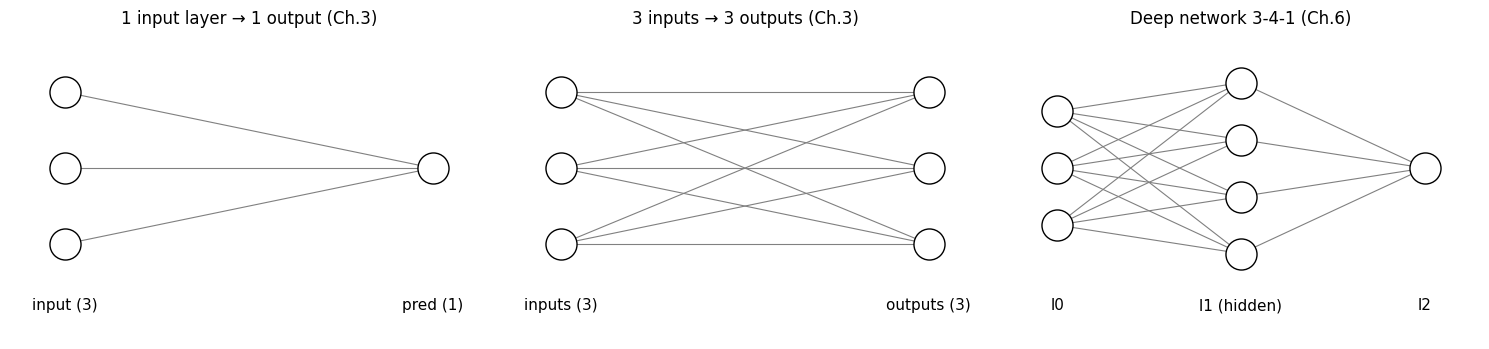

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
os.makedirs("folder-picture", exist_ok=True)

def draw_network(layer_sizes, names=None, ax=None, weight_mats=None):
    """Circles = nodes (vectors), lines = weight matrices."""
    ax = ax or plt.gca()
    maxn = max(layer_sizes)
    xs = np.linspace(0, 1, len(layer_sizes))
    pos = []
    for x, n in zip(xs, layer_sizes):
        ys = (np.arange(n) - (n - 1) / 2) / maxn
        pos.append([(x, y) for y in ys])
    for l in range(len(layer_sizes) - 1):
        for i, (x0, y0) in enumerate(pos[l]):
            for j, (x1, y1) in enumerate(pos[l + 1]):
                if weight_mats is None:
                    ax.plot([x0, x1], [y0, y1], c="gray", lw=0.8, zorder=1)
                else:
                    w = weight_mats[l][i, j]
                    ax.plot([x0, x1], [y0, y1], c="tab:red" if w > 0 else "tab:blue",
                            lw=0.3 + 2.5 * abs(w) / np.abs(weight_mats[l]).max(), alpha=.8, zorder=1)
    for l, pts in enumerate(pos):
        for (x, y) in pts:
            ax.scatter(x, y, s=500, c="white", edgecolors="k", zorder=2)
        if names:
            ax.text(xs[l], -0.62, names[l], ha="center", fontsize=11)
    ax.set_xlim(-0.15, 1.15); ax.set_ylim(-0.75, 0.6); ax.axis("off")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
plt.sca(ax[0]); draw_network([3, 1], ["input (3)", "pred (1)"]); ax[0].set_title("1 input layer → 1 output (Ch.3)")
plt.sca(ax[1]); draw_network([3, 3], ["inputs (3)", "outputs (3)"]); ax[1].set_title("3 inputs → 3 outputs (Ch.3)")
plt.sca(ax[2]); draw_network([3, 4, 1], ["l0", "l1 (hidden)", "l2"]); ax[2].set_title("Deep network 3-4-1 (Ch.6)")
plt.tight_layout()
plt.savefig("folder-picture/ch07_network_pictures.png", dpi=120, bbox_inches="tight")
plt.show()

### 3.2 "Visualizing with letters": the whole of Chapter 6 as a few lines

We solve the Chapter-6 streetlight problem again, but this time written in the compact `l0, l1, l2, W0, W1, d1, d2` notation, **batch-style** (all four examples at once).

In [2]:
np.random.seed(1)
relu  = lambda x: (x > 0) * x
relu2 = lambda y: (y > 0) * 1.0

X = np.array([[1,0,1],[0,1,1],[0,0,1],[1,1,1]])      # l0 for all examples
Y = np.array([[1],[1],[0],[0]])

W0 = 2 * np.random.random((3, 4)) - 1
W1 = 2 * np.random.random((4, 1)) - 1
alpha = 0.2
errs = []
for it in range(400):
    l0 = X
    l1 = relu(l0 @ W0)                 # forward
    l2 = l1 @ W1
    d2 = l2 - Y                        # output delta
    d1 = (d2 @ W1.T) * relu2(l1)       # back-propagated delta
    W1 -= alpha * l1.T @ d2            # (layer before)ᵀ · (delta after)
    W0 -= alpha * l0.T @ d1
    errs.append((d2 ** 2).sum())

print("shapes: l0", X.shape, " W0", W0.shape, " l1", l1.shape, " W1", W1.shape, " l2", l2.shape)
print("predictions:", l2.ravel().round(3), "  targets:", Y.ravel())
print("final error:", round(errs[-1], 8))

shapes: l0 (4, 3)  W0 (3, 4)  l1 (4, 4)  W1 (4, 1)  l2 (4, 1)
predictions: [1. 1. 0. 0.]   targets: [1 1 0 0]
final error: 0.0


### 3.3 Weights as correlation — seeing "correlation summarization"

We train a *single* layer on a dataset where each input has a different, known correlation with the target and compare the **learned weights** with the **measured correlations**.

learned weights : [ 2.  -1.5 -0. ]
correlations    : [ 0.78 -0.56  0.04]


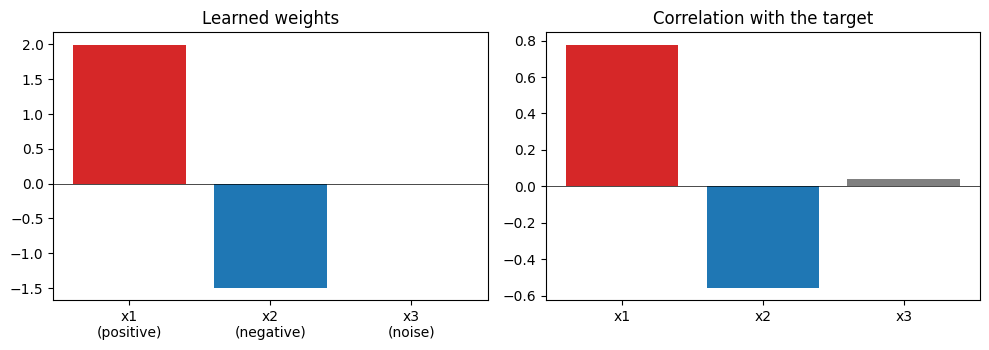

In [3]:
rng = np.random.default_rng(0)
N = 400
x1 = rng.normal(size=N)                  # strongly positive correlation with target
x2 = rng.normal(size=N)                  # strongly negative
x3 = rng.normal(size=N)                  # unrelated noise
y = 2.0 * x1 - 1.5 * x2 + 0.05 * rng.normal(size=N)
X2 = np.c_[x1, x2, x3]

w = np.zeros(3); alpha = 0.002
for epoch in range(300):
    for i in range(N):
        delta = X2[i] @ w - y[i]
        w -= alpha * delta * X2[i]

corr = [np.corrcoef(X2[:, k], y)[0, 1] for k in range(3)]
print("learned weights :", w.round(2))
print("correlations    :", np.round(corr, 2))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].bar(["x1\n(positive)", "x2\n(negative)", "x3\n(noise)"], w, color=["tab:red", "tab:blue", "gray"])
ax[0].set_title("Learned weights"); ax[0].axhline(0, c="k", lw=.5)
ax[1].bar(["x1", "x2", "x3"], corr, color=["tab:red", "tab:blue", "gray"])
ax[1].set_title("Correlation with the target"); ax[1].axhline(0, c="k", lw=.5)
plt.tight_layout()
plt.savefig("folder-picture/ch07_weights_vs_correlation.png", dpi=120, bbox_inches="tight")
plt.show()

The sign of every weight agrees with the sign of the correlation and the noise input gets weight ≈ 0: **weights summarise correlation**.

### 3.4 Drawing the trained network (excite = red, inhibit = blue)

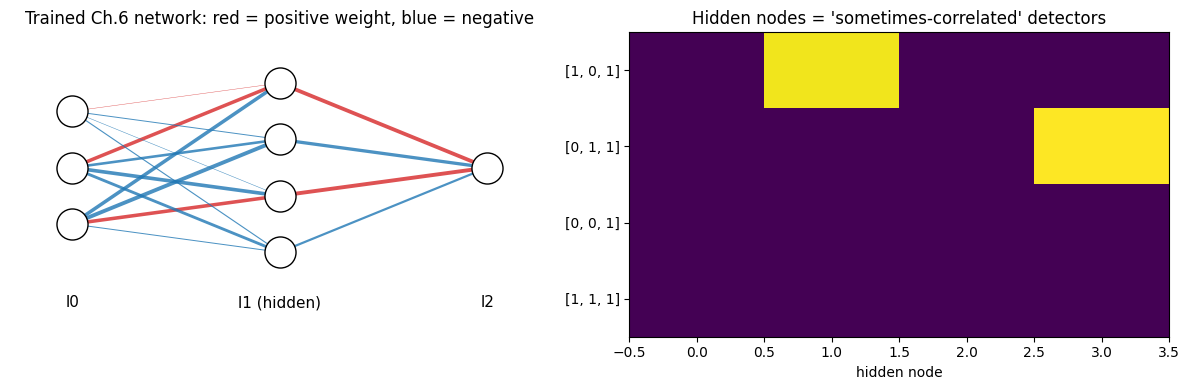

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
plt.sca(ax[0]); draw_network([3, 4, 1], ["l0", "l1 (hidden)", "l2"], weight_mats=[W0, W1])
ax[0].set_title("Trained Ch.6 network: red = positive weight, blue = negative")

hid = relu(X @ W0)
ax[1].imshow(hid, cmap="viridis", aspect="auto")
ax[1].set_xlabel("hidden node"); ax[1].set_yticks(range(4)); ax[1].set_yticklabels([str(r) for r in X.tolist()])
ax[1].set_title("Hidden nodes = 'sometimes-correlated' detectors")
plt.tight_layout()
plt.savefig("folder-picture/ch07_trained_network.png", dpi=120, bbox_inches="tight")
plt.show()

---

## 4. Key Takeaways

* **Correlation summarization:** networks learn by finding direct and indirect correlation between input and output.
* A **layer = vector (row of circles)**, **weights = matrix (lines)**. Any architecture can be sketched this way.
* **Letter notation** (`l0 → l1 → l2`, `W0`, `W1`, `d1`, `d2`) turns an entire training step into a few lines.
* **Shape-checking** (`(1×3)·(3×4)·(4×1)`) is the quickest way to catch bugs.
* Weight update rule everywhere: **`W -= alpha * (layer_before)ᵀ · (delta_after)`**.

➡️ **Next:** Chapter 8 — why networks *overfit* and how **regularization, dropout and mini-batches** fix it.